# LightGBM — Hyperparameter Tuning

Loads the shared train/val/test splits saved by `data_eda.ipynb`, vectorizes with TF-IDF (update the
config below if `bow_vs_tfidf.ipynb` found a better one than the default), then grid-searches
LightGBM's key hyperparameters. Every candidate combination is logged to MLflow, and the best model
gets registered.

Run `data_eda.ipynb` first — this notebook depends on the CSVs it saves.

In [1]:
# ── libraries ──
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from lightgbm import LGBMClassifier, early_stopping, log_evaluation

import mlflow
import mlflow.lightgbm
from mlflow.tracking import MlflowClient

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ── config + load the shared splits ──
MODEL_NAME = "LightGBM"
SEED = 42

DATA_DIR = "../data/processed"
RESULTS_DIR = "results"
MODELS_DIR = "saved_models"
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

MLFLOW_EXPERIMENT = "IndianFinSentiment_ClassicalML"
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment(MLFLOW_EXPERIMENT)

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(f"Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}")

Train: 7094  |  Val: 946  |  Test: 1419


## Vectorize with TF-IDF

**Update these two values** if `bow_vs_tfidf.ipynb` found a better config than this default.

In [3]:
TFIDF_MAX_FEATURES = 15_000
TFIDF_NGRAM_RANGE = (1, 2)

vectorizer = TfidfVectorizer(max_features=TFIDF_MAX_FEATURES, ngram_range=TFIDF_NGRAM_RANGE, min_df=2)
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])
X_test = vectorizer.transform(test_df["text"])

y_train, y_val, y_test = train_df["label_id"], val_df["label_id"], test_df["label_id"]
print(f"TF-IDF matrix shape: {X_train.shape}")

TF-IDF matrix shape: (7094, 11720)


In [4]:
def evaluate(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_weighted": round(f1_score(y_true, y_pred, average="weighted"), 4),
        "f1_positive": round(per_class[0], 4),
        "f1_neutral": round(per_class[1], 4),
        "f1_negative": round(per_class[2], 4),
    }


def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, None]
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm_pct, annot=True, fmt=".1%", cmap="Blues",
                xticklabels=["positive", "neutral", "negative"],
                yticklabels=["positive", "neutral", "negative"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    path = f"{RESULTS_DIR}/cm_{name.lower().replace(' ', '_')}.png"
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    return path

## Broader hyperparameter search (structural params, fixed n_estimators)

The old version only searched `n_estimators` (2) x `max_depth` (2) x `learning_rate` (2) — 8
candidates x 3-fold CV = 24 fits. This version searches the structural hyperparameters that
actually shape each tree — `num_leaves`, `max_depth`, `learning_rate`, `subsample`,
`colsample_bytree`, `reg_alpha`, `reg_lambda`, `class_weight` — with `n_estimators` fixed at a
moderate 300 for this phase, `RandomizedSearchCV` (n_iter=30, cv=3 — heavier fits than the linear
models, so fewer folds), and `verbose=2`.

`n_estimators` deliberately isn't part of this search — the real epochs+early-stopping story
happens in the next section, where LightGBM's *native* boosting-round early stopping picks the
actual optimal tree count directly by watching validation loss every round, which is a much more
direct way to tune that one number than treating it as just another grid value.

In [5]:
model = LGBMClassifier(n_estimators=300, random_state=SEED, verbosity=-1)

param_distributions = {
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 5, 10, 15],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0.0, 0.1, 1.0],
    "reg_lambda": [0.0, 0.1, 1.0],
    "class_weight": [None, "balanced"],
}

start = time.time()
random_search = RandomizedSearchCV(
    model, param_distributions, n_iter=30, cv=3, scoring="f1_weighted",
    n_jobs=-1, random_state=SEED, verbose=2,
)
random_search.fit(X_train, y_train)
search_time = time.time() - start

n_combos = len(random_search.cv_results_["params"])
print(f"\nRandom search done in {search_time:.1f}s — tried {n_combos} combinations x 3-fold CV = {n_combos * 3} fits")
print(f"Best params: {random_search.best_params_}")
print(f"Best CV F1 (weighted): {random_search.best_score_:.4f}")

Fitting 3 folds for each of 30 candidates, totalling 90 fits


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


...

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Random search done in 215.8s — tried 30 combinations x 3-fold CV = 90 fits
Best params: {'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'num_leaves': 31, 'max_depth': 15, 'learning_rate': 0.03, 'colsample_bytree': 0.6, 'class_weight': 'balanced'}
Best CV F1 (weighted): 0.7584


## Log every candidate combination to MLflow

In [6]:
for params, mean_score, std_score in zip(
    random_search.cv_results_["params"],
    random_search.cv_results_["mean_test_score"],
    random_search.cv_results_["std_test_score"],
):
    run_name = f"{MODEL_NAME}_" + "_".join(f"{k}={v}" for k, v in params.items())
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)
        mlflow.log_metric("cv_f1_weighted_mean", round(float(mean_score), 4))
        mlflow.log_metric("cv_f1_weighted_std", round(float(std_score), 4))

print(f"Logged {len(random_search.cv_results_['params'])} candidate runs to MLflow.")

Logged 30 candidate runs to MLflow.


## Overfitting check: train vs val vs test (CV-best structural params, fixed 300 trees)

In [7]:
cv_best_model = random_search.best_estimator_
train_metrics_cv = evaluate(y_train, cv_best_model.predict(X_train))
val_metrics_cv = evaluate(y_val, cv_best_model.predict(X_val))
test_metrics_cv = evaluate(y_test, cv_best_model.predict(X_test))

print(f"{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", train_metrics_cv), ("Val", val_metrics_cv), ("Test", test_metrics_cv)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")

gap = train_metrics_cv["f1_weighted"] - val_metrics_cv["f1_weighted"]
print(f"\nTrain-Val F1 gap: {gap:.4f} (large positive gap = overfitting)")

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Split      Accuracy  F1 (weighted)
Train        0.8496         0.8499
Val          0.7801         0.7804
Test         0.7745         0.7742

Train-Val F1 gap: 0.0695 (large positive gap = overfitting)


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## Real epochs + early stopping: native boosting-round early stopping

LightGBM's boosting rounds *are* epochs — each round adds one more tree, trained on the current
residual error. This retrains the winning structural config with a high ceiling (2,000 rounds).
A custom callback prints **train accuracy, train F1, val accuracy, val F1, test accuracy, and
test F1 every 10 rounds** — not just the internal loss value — so the training is fully visible.
Early stopping still triggers only on validation loss (the `early_stopping()` callback below);
the test numbers are printed purely for visibility and never influence when training stops or
which round gets kept.

In [8]:
best_struct_params = random_search.best_params_


def make_metrics_callback(period=10):
    """Prints train/val/test accuracy AND F1 every `period` boosting rounds — early stopping
    itself still watches validation loss only; this callback is purely for visibility."""
    def _callback(env):
        if (env.iteration + 1) % period == 0 or env.iteration == 0:
            booster = env.model
            n_iter = env.iteration + 1
            tr_pred = np.argmax(booster.predict(X_train, num_iteration=n_iter), axis=1)
            va_pred = np.argmax(booster.predict(X_val, num_iteration=n_iter), axis=1)
            te_pred = np.argmax(booster.predict(X_test, num_iteration=n_iter), axis=1)
            tr_acc, tr_f1 = accuracy_score(y_train, tr_pred), f1_score(y_train, tr_pred, average="weighted")
            va_acc, va_f1 = accuracy_score(y_val, va_pred), f1_score(y_val, va_pred, average="weighted")
            te_acc, te_f1 = accuracy_score(y_test, te_pred), f1_score(y_test, te_pred, average="weighted")
            print(f"Epoch {n_iter:>4} | train_acc={tr_acc:.4f} train_f1={tr_f1:.4f} | "
                  f"val_acc={va_acc:.4f} val_f1={va_f1:.4f} | test_acc={te_acc:.4f} test_f1={te_f1:.4f}")
    _callback.order = 10
    return _callback


es_model = LGBMClassifier(n_estimators=2000, random_state=SEED, verbosity=-1, **best_struct_params)
es_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)], eval_metric="multi_logloss",
    callbacks=[early_stopping(stopping_rounds=30), make_metrics_callback(period=10)],
)

print(f"\nStopped at {es_model.n_estimators_} boosting rounds (best iteration: {es_model.best_iteration_})")

es_test_metrics = evaluate(y_test, es_model.predict(X_test))
es_val_metrics = evaluate(y_val, es_model.predict(X_val))
es_train_metrics = evaluate(y_train, es_model.predict(X_train))
print(f"\n{'Split':<8} {'Accuracy':>10} {'F1 (weighted)':>14}")
for name, m in [("Train", es_train_metrics), ("Val", es_val_metrics), ("Test", es_test_metrics)]:
    print(f"{name:<8} {m['accuracy']:>10.4f} {m['f1_weighted']:>14.4f}")

Epoch    1 | train_acc=0.6596 train_f1=0.6529 | val_acc=0.6448 val_f1=0.6347 | test_acc=0.6589 test_f1=0.6528
Training until validation scores don't improve for 30 rounds


Epoch   10 | train_acc=0.7451 train_f1=0.7452 | val_acc=0.7241 val_f1=0.7238 | test_acc=0.7259 test_f1=0.7249


Epoch   20 | train_acc=0.7506 train_f1=0.7508 | val_acc=0.7199 val_f1=0.7198 | test_acc=0.7329 test_f1=0.7333


Epoch   30 | train_acc=0.7585 train_f1=0.7587 | val_acc=0.7315 val_f1=0.7314 | test_acc=0.7315 test_f1=0.7316


Epoch   40 | train_acc=0.7647 train_f1=0.7650 | val_acc=0.7378 val_f1=0.7378 | test_acc=0.7336 test_f1=0.7340


...

Epoch  500 | train_acc=0.8823 train_f1=0.8825 | val_acc=0.7918 val_f1=0.7920 | test_acc=0.7780 test_f1=0.7774


Early stopping, best iteration is:
[479]	valid_0's multi_logloss: 0.541116

Stopped at 479 boosting rounds (best iteration: 479)


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Split      Accuracy  F1 (weighted)
Train        0.8779         0.8781
Val          0.7907         0.7909
Test         0.7773         0.7767


In [9]:
# ── the early-stopped model (best hyperparameters, trained epoch-by-epoch — each boosting round
# is an epoch — with early stopping) is the final model — always. CV-best (fixed 300 trees,
# one-shot) is kept as an informational reference point only. ──
print(f"{'Model':<32} {'F1 (weighted)':>14} {'Accuracy':>10}")
print("-" * 58)
print(f"{'CV-best (300 trees, one-shot)':<32} {test_metrics_cv['f1_weighted']:>14.4f} {test_metrics_cv['accuracy']:>10.4f}")
print(f"{'Early-stopped (' + str(es_model.best_iteration_) + ' trees)':<32} {es_test_metrics['f1_weighted']:>14.4f} {es_test_metrics['accuracy']:>10.4f}")

final_model, final_variant, final_test_metrics = es_model, f"EarlyStopped_{es_model.best_iteration_}trees", es_test_metrics
print(f"\nFinal model (epoch-trained, best hyperparameters): {MODEL_NAME} ({final_variant})")

Model                             F1 (weighted)   Accuracy
----------------------------------------------------------
CV-best (300 trees, one-shot)            0.7742     0.7745
Early-stopped (479 trees)                0.7767     0.7773

Final model (epoch-trained, best hyperparameters): LightGBM (EarlyStopped_479trees)


## Evaluate the best model on the held-out test set

/Users/vijay/Desktop/sentiment-drl-trading/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


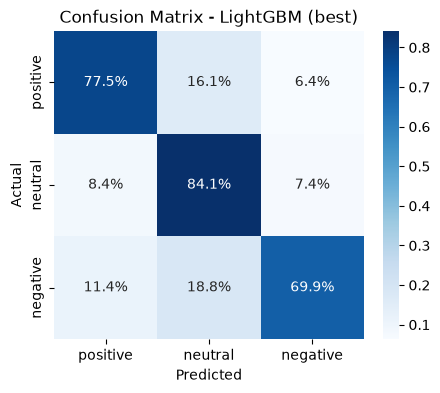

2026/07/19 16:58:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/07/19 16:59:26 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /var/folders/n8/vj4s_ql15hzf0pccx67nz0lc0000gn/T/tmpq_pcif50/model, flavor: lightgbm). Fall back to return ['lightgbm==4.6.0', 'skops==0.14.0']. Set logging level to DEBUG to see the full traceback. 



LightGBM (EarlyStopped_479trees) — TEST RESULTS
              precision    recall  f1-score   support

    positive       0.81      0.78      0.79       503
     neutral       0.73      0.84      0.78       511
    negative       0.80      0.70      0.75       405

    accuracy                           0.78      1419
   macro avg       0.78      0.77      0.77      1419
weighted avg       0.78      0.78      0.78      1419



In [10]:
test_preds = final_model.predict(X_test)
test_metrics = evaluate(y_test, test_preds)

with mlflow.start_run(run_name=f"{MODEL_NAME}_BEST_{final_variant}"):
    mlflow.log_params({"variant": final_variant, **best_struct_params})
    mlflow.log_param("n_estimators", getattr(final_model, "best_iteration_", None) or final_model.n_estimators)
    mlflow.log_param("tfidf_max_features", TFIDF_MAX_FEATURES)
    mlflow.log_param("tfidf_ngram_range", str(TFIDF_NGRAM_RANGE))
    mlflow.log_metrics(test_metrics)
    mlflow.log_metric("search_time_seconds", round(search_time, 2))

    cm_path = plot_confusion_matrix(y_test, test_preds, f"{MODEL_NAME} (best)")
    mlflow.log_artifact(cm_path)
    mlflow.lightgbm.log_model(final_model, "model")
    run_id = mlflow.active_run().info.run_id

print(f"\n{MODEL_NAME} ({final_variant}) — TEST RESULTS")
print(classification_report(y_test, test_preds, target_names=["positive", "neutral", "negative"]))

with open(f"{MODELS_DIR}/{MODEL_NAME.lower()}_best.pkl", "wb") as f:
    pickle.dump({"vectorizer": vectorizer, "model": final_model, "variant": final_variant}, f)

## Register the best model in the MLflow Model Registry

In [11]:
client = MlflowClient()
try:
    registered = mlflow.register_model(model_uri=f"runs:/{run_id}/model", name=f"{MODEL_NAME}_Classifier")
    print(f"Registered '{MODEL_NAME}_Classifier' version {registered.version}")
except Exception as e:
    print(f"Registration skipped/failed: {e}")

print(f"\nBest {MODEL_NAME} test F1 (weighted): {test_metrics['f1_weighted']:.4f}")

Registered model 'LightGBM_Classifier' already exists. Creating a new version of this model...


2026/07/19 16:59:28 WARNING mlflow.tracking._model_registry.fluent: Run with id 50181fe62224424ea70017aeb24bac20 has no artifacts at artifact path 'model', registering model based on models:/m-f1ae60c814d2443d87baa1450d73b7aa instead


Registered 'LightGBM_Classifier' version 4

Best LightGBM test F1 (weighted): 0.7767


Created version '4' of model 'LightGBM_Classifier'.
